In [1]:
import os, sys
from pathlib import Path
import pandas as pd

print("工作目录:", os.getcwd())
print("解释器 :", sys.executable)

root = Path.cwd() if (Path.cwd() / "data/raw/Churn_Modelling.csv").exists() else Path.cwd().parent
df = pd.read_csv(root / "data/raw/Churn_Modelling.csv")
print("数据规模:", df.shape)



工作目录: D:\Users\swm\Desktop\banking_client_demo\notebooks
解释器 : C:\Users\swm\.conda\envs\pytorch_env\python.exe
数据规模: (10000, 14)


In [4]:
print("缺失单元格:", df.isna().sum().sum())
print("重复行:", df.duplicated().sum())
print("重复客户编号:", df["CustomerId"].duplicated().sum())
print("\n标签分布:\n", df["Exited"].value_counts(normalize=True).round(4))
print("\n各地区人数:\n", df["Geography"].value_counts())
print("\n余额为 0 的人数:", (df["Balance"] == 0).sum())


缺失单元格: 0
重复行: 0
重复客户编号: 0

标签分布:
 Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

各地区人数:
 Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

余额为 0 的人数: 3617


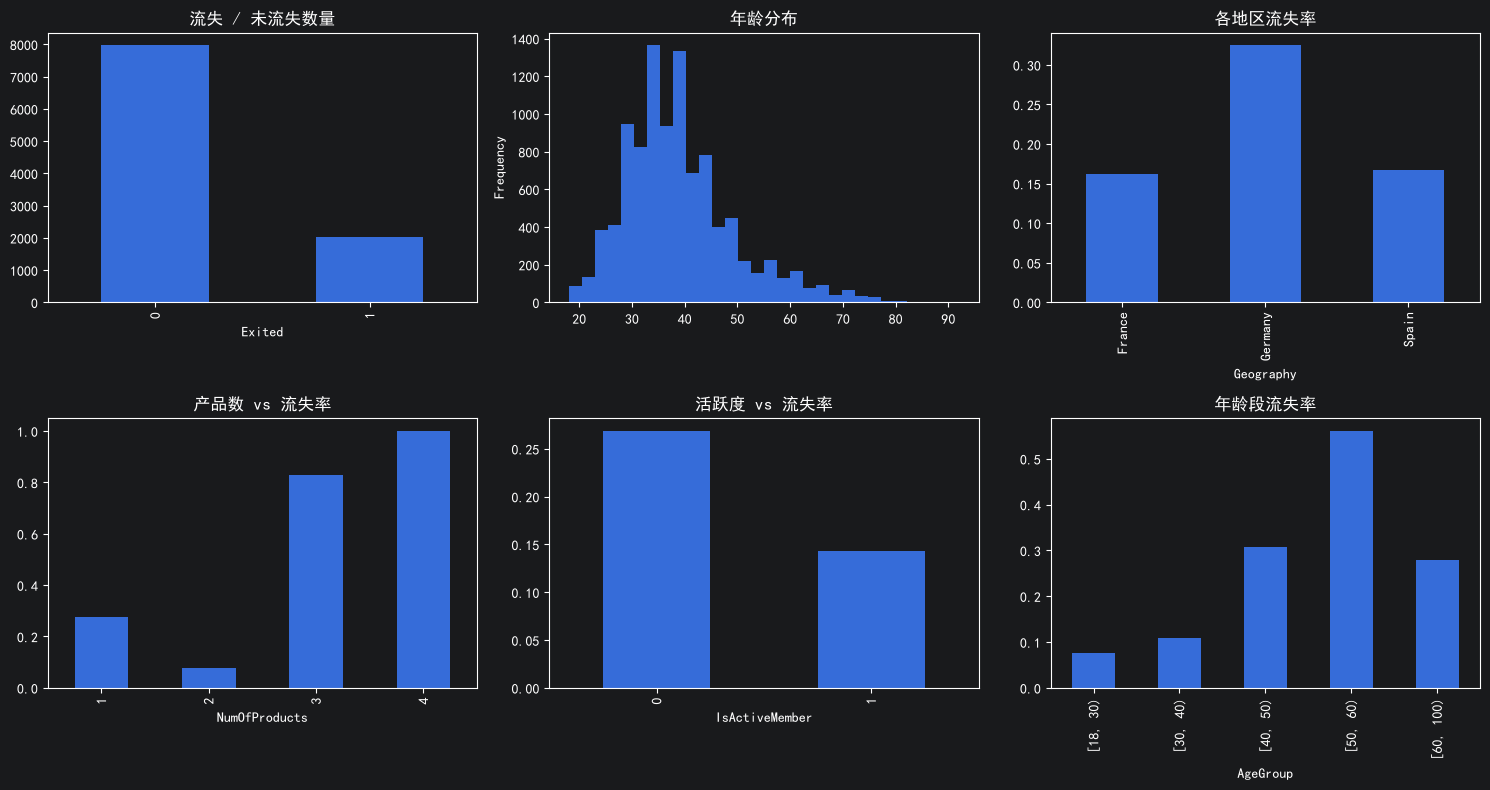

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

df["Exited"].value_counts().sort_index().plot(kind="bar", ax=axes[0,0])
axes[0,0].set_title("流失 / 未流失数量")

df["Age"].plot(kind="hist", bins=30, ax=axes[0,1])
axes[0,1].set_title("年龄分布")

df.groupby("Geography")["Exited"].mean().plot(kind="bar", ax=axes[0,2])
axes[0,2].set_title("各地区流失率")

df.groupby("NumOfProducts")["Exited"].mean().plot(kind="bar", ax=axes[1,0])
axes[1,0].set_title("产品数 vs 流失率")

df.groupby("IsActiveMember")["Exited"].mean().plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("活跃度 vs 流失率")

df["AgeGroup"] = pd.cut(df["Age"], bins=[18,30,40,50,60,100], right=False)
df.groupby("AgeGroup", observed=True)["Exited"].mean().plot(kind="bar", ax=axes[1,2])
axes[1,2].set_title("年龄段流失率")

plt.tight_layout()
plt.savefig(root / "reports" / "eda_charts.png", dpi=150)


# EDA 分析结论

## 1. 标签分布
未流失 7963 人、流失 2037 人，流失率 20.37%。类别存在不平衡：
若模型把所有人预测为"不流失"，准确率仍有 79.63%，
因此 Accuracy 不能作为主评价指标，应以 Recall 和 PR-AUC 为主。

## 2. 年龄
流失率随年龄上升，50-59 组最高，为 56.04%；但 60+ 组回落到 27.95%。
该组仅 526 人，样本量小，这个回落不宜直接解释为业务规律。

## 3. 地区
Germany 32.44%、Spain 16.67%、France 16.15%。Germany 只有 2509 人，
France 有 5014 人；若改用流失人数（814 对 810）会误判两地风险相同，
所以必须比较流失率而不是流失人数。

## 4. 产品数
1/2/3/4 个产品的流失率分别为 27.71 / 7.58 / 82.71 / 100 %。
其中 3 产品组仅 266 人、4 产品组仅 60 人且全部流失，
小样本加标签高度同质，很可能是数据采集口径造成的，不宜当作可靠规律。

## 5. 活跃度
非活跃 26.85%、活跃 14.27%，相差约 12.6 个百分点，
是本次 EDA 中最强的单特征信号。
